# Step #1 Load the Data

In [ ]:
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, TensorFlow 2.21, Keras 3.15, pandas 3.0, and yfinance 1.5

import keras
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import yfinance as yf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})
keras.utils.set_random_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(tf.config.list_physical_devices('GPU'))}")

# Use a fixed, recent endpoint so the tutorial produces reproducible train/test sets.
start_date = "2010-01-01"
end_date = "2026-01-01"
stock_name = "S&P 500"
symbol = "^GSPC"

df = yf.download(
    symbol,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    multi_level_index=False,
    progress=False,
)
if df.empty:
    raise RuntimeError("yfinance returned no data for ^GSPC")

print(df.shape)
df.head()

TensorFlow version: 2.21.0
Available GPUs: 0
(4024, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,1132.989990,1133.869995,1116.560059,1116.560059,3991400000
2010-01-05,1136.520020,1136.630005,1129.660034,1132.660034,2491020000
2010-01-06,1137.140015,1139.189941,1133.949951,1135.709961,4972660000
2010-01-07,1141.689941,1142.459961,1131.319946,1136.270020,5270680000
2010-01-08,1144.979980,1145.390015,1136.219971,1140.520020,4389590000


: 

# Step #2 Define the Forecast Horizon and Explore the Data

In [2]:
# Predict the close five trading sessions after the final input observation.
forecast_horizon = 5
close_prices = df[["Close"]].dropna().copy()

print(f"Observations: {len(close_prices):,}")
print(f"Direct forecast horizon: {forecast_horizon} trading sessions")
close_prices.head()

Observations: 4,024
Direct forecast horizon: 5 trading sessions


,Close
Date,
2010-01-04,1132.989990
2010-01-05,1136.520020
2010-01-06,1137.140015
2010-01-07,1141.689941
2010-01-08,1144.979980


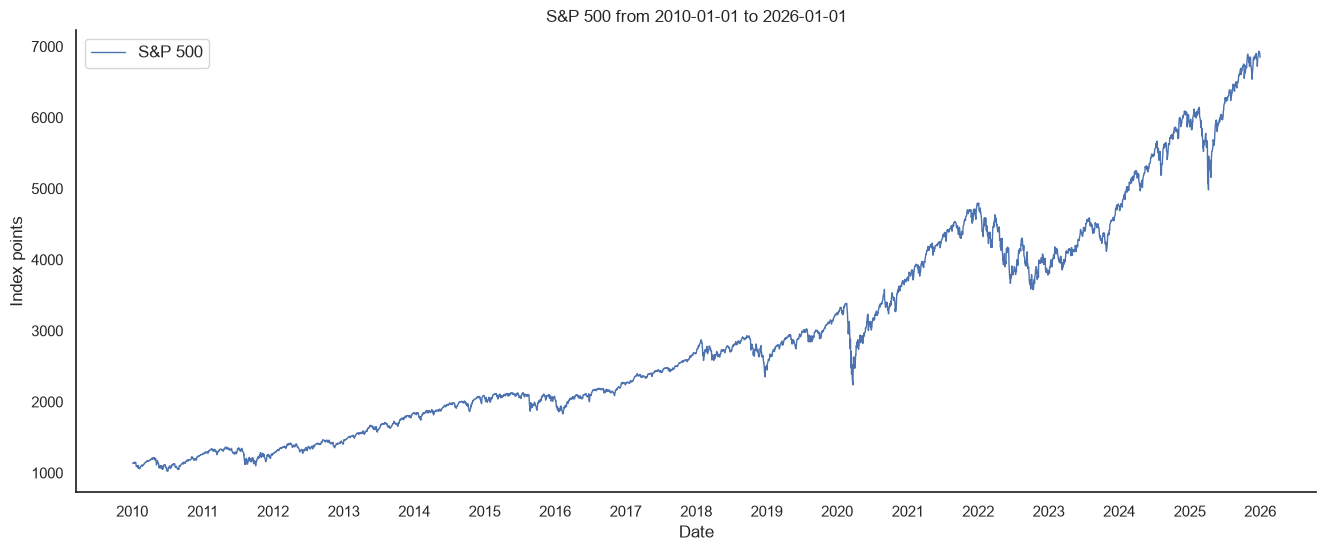

In [3]:
years = mdates.YearLocator()
_, ax = plt.subplots(figsize=(16, 6))
ax.xaxis.set_major_locator(years)
sns.lineplot(x=close_prices.index, y=close_prices["Close"], ax=ax, label=stock_name, linewidth=1.0)
ax.set_title(f"{stock_name} from {start_date} to {end_date}")
ax.set_ylabel("Index points")
ax.legend(fontsize=12)
plt.show()

# Step #3 Preprocess the Data

In [4]:
train_size = int(len(close_prices) * 0.8)

# Fit preprocessing on the training period only to avoid leaking future price ranges.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(close_prices.iloc[:train_size])
scaled_prices = scaler.transform(close_prices)

In [5]:
sequence_length = 50


def create_direct_horizon_sequences(values, sequence_length, forecast_horizon):
    features, targets, target_indices = [], [], []
    for input_end in range(sequence_length, len(values) - forecast_horizon + 1):
        target_index = input_end + forecast_horizon - 1
        features.append(values[input_end - sequence_length:input_end])
        targets.append(values[target_index, 0])
        target_indices.append(target_index)

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(target_indices),
    )


x_all, y_all, target_indices = create_direct_horizon_sequences(
    scaled_prices,
    sequence_length,
    forecast_horizon,
)
train_mask = target_indices < train_size
x_train, y_train = x_all[train_mask], y_all[train_mask]
x_test, y_test = x_all[~train_mask], y_all[~train_mask]
test_target_indices = target_indices[~train_mask]
test_index = close_prices.index[test_target_indices]

print(f"Training shapes: {x_train.shape}, {y_train.shape}")
print(f"Test shapes: {x_test.shape}, {y_test.shape}")

# The first held-out target is five trading sessions after its final input value.
assert test_target_indices[0] == train_size
assert np.isclose(
    x_test[0, -1, 0],
    scaled_prices[test_target_indices[0] - forecast_horizon, 0],
)
print(
    "First held-out forecast:",
    close_prices.index[test_target_indices[0] - forecast_horizon].date(),
    "->",
    test_index[0].date(),
)

Training shapes: (3165, 50, 1), (3165,)
Test shapes: (805, 50, 1), (805,)
First held-out forecast: 2022-10-10 -> 2022-10-17


# Step #4 Train the Model

In [6]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(sequence_length, 1)),
        keras.layers.LSTM(50, return_sequences=True),
        keras.layers.LSTM(50),
        keras.layers.Dense(25, activation="relu"),
        keras.layers.Dense(1),
    ],
    name="sp500_five_session_lstm",
)
model.compile(optimizer=keras.optimizers.Adam(), loss="mean_squared_error")
model.summary()

Model: "sp500_five_session_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)
history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 0.0011 - val_loss: 0.0034
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0022 - val_loss: 0.0029
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0023 - val_loss: 0.0025
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0014 - val_loss: 0.0019
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 9.5751e-04 - val_loss: 0.0021
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0011 - val_loss: 0.0026
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0016 - val_loss: 0.0031


# Step #5 Evaluate Model Performance

LSTM MAE: 436.62 index points
LSTM RMSE: 556.19 index points
LSTM MAPE: 7.52%
LSTM median absolute percentage error: 6.88%
Persistence baseline MAE: 80.45 index points
Persistence baseline RMSE: 107.08 index points


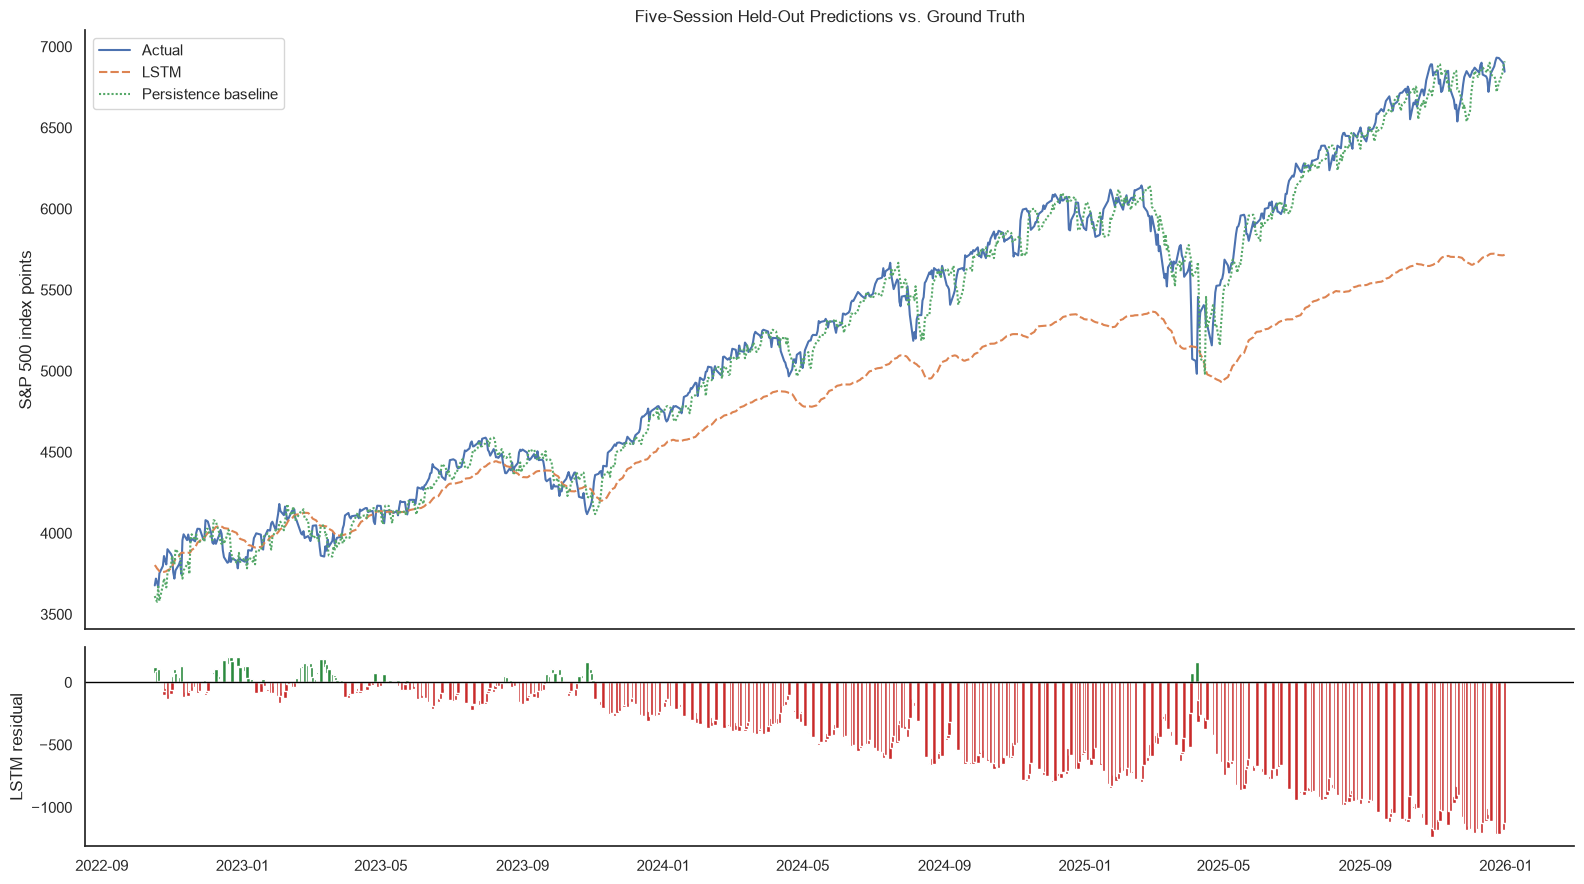

In [8]:
y_pred_scaled = model.predict(x_test, verbose=0)
y_pred = scaler.inverse_transform(y_pred_scaled).ravel()
y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

absolute_percentage_errors = np.abs((y_test_unscaled - y_pred) / y_test_unscaled) * 100
mae = mean_absolute_error(y_test_unscaled, y_pred)
rmse = root_mean_squared_error(y_test_unscaled, y_pred)
mape = absolute_percentage_errors.mean()
median_ape = np.median(absolute_percentage_errors)

# A five-session persistence forecast uses the last close available at each forecast origin.
naive_pred = close_prices["Close"].iloc[
    test_target_indices - forecast_horizon
].to_numpy()
naive_mae = mean_absolute_error(y_test_unscaled, naive_pred)
naive_rmse = root_mean_squared_error(y_test_unscaled, naive_pred)

print(f"LSTM MAE: {mae:.2f} index points")
print(f"LSTM RMSE: {rmse:.2f} index points")
print(f"LSTM MAPE: {mape:.2f}%")
print(f"LSTM median absolute percentage error: {median_ape:.2f}%")
print(f"Persistence baseline MAE: {naive_mae:.2f} index points")
print(f"Persistence baseline RMSE: {naive_rmse:.2f} index points")

evaluation = pd.DataFrame(
    {
        "Actual": y_test_unscaled,
        "LSTM": y_pred,
        "Persistence baseline": naive_pred,
    },
    index=test_index,
)
evaluation["LSTM residual"] = evaluation["LSTM"] - evaluation["Actual"]

_, (ax_price, ax_error) = plt.subplots(
    2,
    1,
    figsize=(16, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)
sns.lineplot(data=evaluation[["Actual", "LSTM", "Persistence baseline"]], ax=ax_price)
ax_price.set_title("Five-Session Held-Out Predictions vs. Ground Truth")
ax_price.set_ylabel("S&P 500 index points")

colors = np.where(evaluation["LSTM residual"] >= 0, "#2B8A3E", "#C92A2A")
ax_error.bar(evaluation.index, evaluation["LSTM residual"], width=3, color=colors)
ax_error.axhline(0, color="black", linewidth=1)
ax_error.set_ylabel("LSTM residual")
plt.tight_layout()
plt.show()

# Step #6 Predict Five Trading Sessions Ahead

In [9]:
last_sequence_scaled = scaler.transform(close_prices.iloc[-sequence_length:])
x_next = last_sequence_scaled[np.newaxis, ...].astype(np.float32)
forecast_close_scaled = model.predict(x_next, verbose=0)
forecast_close = float(scaler.inverse_transform(forecast_close_scaled)[0, 0])

last_date = close_prices.index[-1].date()
last_close = float(close_prices["Close"].iloc[-1])
percent_change = (forecast_close / last_close - 1) * 100

print(f"Last observed {stock_name} close on {last_date}: {last_close:.2f}")
print(
    f"Illustrative {forecast_horizon}-session prediction: "
    f"{forecast_close:.2f} ({percent_change:+.2f}%)"
)

Last observed S&P 500 close on 2025-12-31: 6845.50
Illustrative 5-session prediction: 5736.89 (-16.19%)
